In [1]:
%pip install -q requests pydantic python-dotenv pandas matplotlib numpy pymilvus pypdf

Note: you may need to restart the kernel to use updated packages.


In [35]:
import os, re, sys, json, time, hashlib, threading
from pathlib import Path
from dataclasses import dataclass, field
from concurrent.futures import ThreadPoolExecutor
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field
from pymilvus import MilvusClient

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass
try:
    os.environ.setdefault("OPENROUTER_API_KEY", UserSecretsClient().get_secret("OPENROUTER_API_KEY"))
except Exception:
    pass
assert os.getenv("OPENROUTER_API_KEY"), "нет ключа: положите его в .env рядом с ноутбуком или в Kaggle Secrets"

CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}",
           "HTTP-Referer": "https://postypashki.ru", "X-Title": "agents-course-seminar01"}
MODELS = {
          "cheap": "openai/gpt-4o-mini",
          #"cheap": "qwen/qwen-2.5-72b-instruct",
          "mid": "anthropic/claude-haiku-4.5",
          "strong": "anthropic/claude-sonnet-4.6"
          }
EMBED_URL = "https://openrouter.ai/api/v1/embeddings"
EMBED_MODEL, DIM = "openai/text-embedding-3-small", 512
DATA = next((p for p in [Path("data"), Path("/kaggle/input/seminar02-data"), Path("/kaggle/input/seminar02-data/data")]
             if (p / "corpus_2026.jsonl").exists()), Path("data"))
Path("img").mkdir(exist_ok=True)

COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}

TRACES, IMG = Path("traces"), Path("img")
TRACES.mkdir(exist_ok=True)
IMG.mkdir(exist_ok=True)



@dataclass
class Ledger:
    calls: list = field(default_factory=list)
    local: threading.local = field(default_factory=threading.local)

    def add(self, tag, model, usage, seconds=0.0):
        cost = usage.get("cost") or 0.0
        self.calls.append({"tag": tag, "model": model.split("/")[-1], "prompt": usage.get("prompt_tokens", 0),
                           "completion": usage.get("completion_tokens", 0), "cost": cost, "seconds": round(seconds, 2)})
        self.local.spent = self.mine + cost
        return cost

    @property
    def total(self):
        return sum(c["cost"] for c in self.calls)

    @property
    def mine(self):
        return getattr(self.local, "spent", 0.0)

    def table(self):
        frame = pd.DataFrame(self.calls, columns=["tag", "model", "prompt", "completion", "cost", "seconds"])
        return frame.groupby(["tag", "model"]).agg(calls=("cost", "size"), prompt=("prompt", "sum"),
                                                                      completion=("completion", "sum"), cost=("cost", "sum")).round(5)


ledger = Ledger()


# контроль попыток: обёртка над запросами. Выход: грязный ответ модели в Json или ошибка
def post_with_retry(url, body, attempts=5):
    for attempt in range(attempts):
        r = requests.post(url, json=body, headers=HEADERS, timeout=120)
        if r.status_code == 200:
            return r.json()
        if r.status_code in (429, 500, 502, 503) and attempt < attempts - 1:
            time.sleep(1.5 * (attempt+1))
            continue
        raise RuntimeError(f"HTTP {r.status_code} : {r.text[:5000]}")


# чат с моделью. Контроль температуры и tools, учёт токенов. Выход: чистый ответ модели
def chat(messages, model, tools=None, tag="chat"):
    body = {"model": model, "messages": messages, "temperature": 0, "usage": {"include": True}}
    if tools:
        body["tools"] = tools
    started = time.perf_counter()
    data = post_with_retry(CHAT_URL, body)
    ledger.add(tag, model, data.get("usage") or {}, time.perf_counter() - started)
    return data["choices"][0]["message"]


def load_jsonl(name):
    name = Path(name)
    return [json.loads(line) for line in (name).read_text(encoding="utf-8").splitlines() if line.strip()]

## Корпус и нарезка

In [2]:
# данные о корпусе
corpus, tasks = load_jsonl("data/corpus.jsonl"), load_jsonl("data/fresh.jsonl")
len(corpus), sum(len(p["text"]) for p in corpus), len(tasks), tasks[0]

(27,
 348727,
 40,
 {'id': 'f1-01',
  'source': 'wikipedia',
  'question': "Who won the 2025 Formula One World Drivers' Championship?",
  'answer': 'Lando Norris',
  'evidence': "The season saw Lando Norris win his first drivers' title in his seventh season in the sport, ending the four-year reign of Max Verstappen as champion.",
  'page': '2025 Formula One World Championship',
  'url': 'https://en.wikipedia.org/wiki/2025_Formula_One_World_Championship'})

In [3]:
# нарезка 2-мя разными способами
def chunk_lines(page):
    chunks, section = [], ""
    for line in page["text"].splitlines():
        line = " ".join(line.split())
        if line.startswith("="):
            section = line.strip('= ')
        elif len(line) > 40:
            chunks.append({"page": page["page"], "section": section, "url" : page["url"], "text": line})
    return chunks
    
    
def chunk_chars_400(page, size=400):
    text = " ".join(page["text"].split())
    return [{"page": page["page"], "section": "", "url": page["url"], "text": text[i:i + size]} for i in range(0, len(text), size)]

def chunk_chars_1200(page, size=1200):
    text = " ".join(page["text"].split())
    return [{"page": page["page"], "section": "", "url": page["url"], "text": text[i:i + size]} for i in range(0, len(text), size)]

line_chunks = [c for p in corpus for c in chunk_lines(p)]
char_chunks_400 = [c for p in corpus for c in chunk_chars_400(p)]
char_chunks_1200 = [c for p in corpus for c in chunk_chars_1200(p)]

len(line_chunks), len(char_chunks_400), len(char_chunks_1200), line_chunks[100]

(757,
 883,
 304,
 {'page': '2025 São Paulo Grand Prix',
  'section': 'Tyre choices',
  'url': 'https://en.wikipedia.org/wiki/2025_S%C3%A3o_Paulo_Grand_Prix',
  'text': 'Tyre supplier Pirelli brought the C2, C3, and C4 tyre compounds designated hard, medium, and soft, respectively, for teams to use at the event, a step harder than the previous year.'})

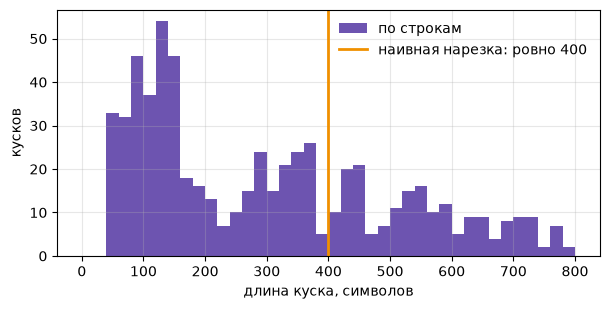

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist([len(c["text"]) for c in line_chunks], bins=40, range=(0, 800), color=COLORS["violet"], alpha=0.85, label="по строкам")
ax.axvline(400, color=COLORS["amber"], lw=2, label="наивная нарезка: ровно 400")
ax.set_xlabel("длина куска, символов"); ax.set_ylabel("кусков"); ax.legend(frameon=False); ax.grid(alpha=0.3);

## Спринт 2. Эмбеддинги и кэш

In [5]:
DATA = Path('data')
EMB = {}

def load_cache():
    for path in [DATA / "embeddings_512.npz", Path("emb_cache.npz")]:
        if path.exists():
            z = np.load(path)
            EMB.update({str(k): v.astype(np.float32) for k, v in zip(z["keys"], z["vectors"])})
    return len(EMB)

def save_cache():
    np.savez_compressed("emb_cache.npz", keys=np.array(list(EMB)), vectors=np.stack(list(EMB.values())).astype(np.float16))

def embed_batch(texts):
    started = time.perf_counter()
    data = post_with_retry(EMBED_URL, {"model": EMBED_MODEL, "input": texts, "dimensions": DIM})
    ledger.add("embed", EMBED_MODEL, data.get("usage") or {}, time.perf_counter() - started)
    return [row["embedding"] for row in data["data"]]

def key_of(text):
    return hashlib.sha1(text.encode("utf-8")).hexdigest()

load_cache()

1975

In [6]:
def embed_cached(texts):
    missing = list(dict.fromkeys(t for t in texts if key_of(t) not in EMB)) #set нельзя т.к. нет порядка
    for i in range(0, len(missing), 64):
        batch = missing[i:i+64]
        for text, vector in zip(batch, embed_batch(batch)):
            EMB[key_of(text)] = np.asarray(vector, dtype=np.float32)

    vectors = np.stack([EMB[key_of(t)] for t in texts])
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
        


In [8]:
def emb_text(chunk):
    return f"{chunk['page']}: {chunk['text']}"

line_vecs = embed_cached([emb_text(c) for c in line_chunks])
char_vecs_400 = embed_cached([c["text"] for c in char_chunks_400])
char_vecs_1200 = embed_cached([c["text"] for c in char_chunks_1200])

q_vecs = embed_cached([t["question"] for t in tasks])
save_cache()
line_vecs.shape, char_vecs_400.shape, char_vecs_1200.shape, q_vecs.shape

((757, 512), (883, 512), (304, 512), (40, 512))

## Поиск на numpy и recall@k

In [9]:
# вычисление лидеров по сходству
def search_numpy(query_vec, vectors, k=5):
    sims = vectors @ query_vec
    top = np.argsort(-sims)[:k]
    return[(int(i), float(sims[i])) for i in top]

In [10]:
NUMBERS = {word: str(n) for n, word in enumerate("zero one two three four five six seven eight nine ten eleven twelve".split())}

def norm(text):
    words = re.sub(r"\b(a|an|the)\b|[^\w\s]", " ", str(text).lower()).split()
    return " ".join(NUMBERS.get(w, w) for w in words)

def is_gold(chunk, task):
    if chunk["page"] != task["page"]:
        return False
    text, words = norm(chunk["text"]), norm(task["evidence"]).split()
    return norm(task["answer"]) in text and sum(w in text for w in words) >= 0.5 * len(words)

def recall_curve(chunks, vectors, ks=(1, 3, 5, 10, 20)):
    ranked = [[i for i, _ in search_numpy(q, vectors, max(ks))] for q in q_vecs]
    return {k: float(np.mean([any(is_gold(chunks[i], t) for i in r[:k]) for r, t in zip(ranked, tasks)])) for k in ks}

# for i, score in search_numpy(q_vecs[0], line_vecs, 3):
#     print(round(score, 3), "|", line_chunks[i]["page"], "|", line_chunks[i]["text"][:110])
# tasks[0]["question"], tasks[0]["answer"]

,по строкам,по 400 символов,по 1200 символов
1,0.32,0.22,0.62
3,0.38,0.35,0.70
5,0.40,0.38,0.72
10,0.52,0.48,0.72
20,0.68,0.52,0.72


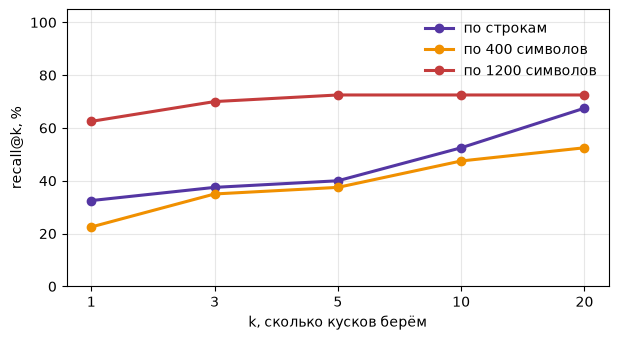

In [14]:
curves = {"по строкам": recall_curve(line_chunks, line_vecs), "по 400 символов": recall_curve(char_chunks_400, char_vecs_400), "по 1200 символов": recall_curve(char_chunks_1200, char_vecs_1200)}
fig, ax = plt.subplots(figsize=(7, 3.6))
for (name, curve), color in zip(curves.items(), [COLORS["violet"], COLORS["amber"], COLORS["red"]]):
    ax.plot([str(k) for k in curve], [v * 100 for v in curve.values()], marker="o", lw=2.2, color=color, label=name)
ax.set_xlabel("k, сколько кусков берём"); ax.set_ylabel("recall@k, %"); ax.set_ylim(0, 105); ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig("img/recall.png", dpi=150, bbox_inches="tight")
pd.DataFrame(curves).round(2)

## Milvus


In [15]:
pip install "pymilvus[milvus-lite]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 269.6/269.6 kB 1.3 MB/s eta 0:00:00a 0:00:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 5.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 6.0 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


In [16]:
from pymilvus import MilvusClient

In [17]:
MILVUS_URI = os.getenv("MILVUS_URI", "http://localhost:19530")
#client = MilvusClient(uri=MILVUS_URI, token=os.getenv("MILVUS_TOKEN", ""))
client = MilvusClient("milvus_local.db")

if os.getenv("MILVUS_DB"):
    if os.environ["MILVUS_DB"] not in client.list_databases():
        client.create_database(os.environ["MILVUS_DB"])
    client.use_database(os.environ["MILVUS_DB"])
client.get_server_version(), client.list_collections()

('milvus_lite-3.2.1', [])

In [24]:
def index_to_milvus(name, chunks, vectors):
    if client.has_collection(name):
        client.drop_collection()
    client.create_collection(name, dimension=vectors.shape[1], metric_type="COSINE")
    rows = [{"id": i, "vector": v.tolist(), **c} for i, (c, v) in enumerate(zip(chunks, vectors))]
    for i in range(0, len(rows), 1000):
        client.insert(name, rows[i:i+1000])

    client.flush(name)
    return client.get_collection_stats(name)

In [25]:
def search_milvus(name, query, k=5, flt=""):
    vector = embed_cached([query])[0].tolist()
    hits = client.search(name, data=[vector], limit=k, filter=flt, output_fields=["page", "section", "url", "text"])[0]

    return [{**h['entity'], "id": h["id"], "score": round(h["distance"], 4)} for h in hits ]
    

In [ ]:
index_to_milvus("char_1200", char_chunks_1200, char_vecs_1200), client.describe_index("char_1200", "vector")

({'row_count': 304},
 {'index_type': 'AUTOINDEX',
  'metric_type': 'COSINE',
  'field_name': 'vector',
  'index_name': 'vector',
  'total_rows': 304,
  'indexed_rows': 304,
  'pending_index_rows': 0,
  'state': 'Finished'})

I1012 22:38:18.930640    9285 chttp2_transport.cc:1400] ipv4:127.0.0.1:33585: Got goaway [11] err=UNAVAILABLE:GOAWAY received; Error code: 11; Debug Text: too_many_pings {http2_error:11}
E1012 22:38:18.936241    9285 chttp2_transport.cc:1432] ipv4:127.0.0.1:33585: Received a GOAWAY with error code ENHANCE_YOUR_CALM and debug data equal to "too_many_pings". Current keepalive time (before throttling): 40000ms


In [28]:
pd.DataFrame(search_milvus("char_1200", tasks[0]["question"], 3))[["score", "page", "section", "text"]]

,score,page,section,text
0,0.7004,2025 Formula One World Championship,,The 2025 FIA Formula One World Championship wa...
1,0.6698,2025 Abu Dhabi Grand Prix,,The 2025 Abu Dhabi Grand Prix (officially know...
2,0.6529,2025 Singapore Grand Prix,,The 2025 Singapore Grand Prix (officially know...


I1012 22:53:17.233976    9280 chttp2_transport.cc:1400] ipv4:127.0.0.1:33585: Got goaway [11] err=UNAVAILABLE:GOAWAY received; Error code: 11; Debug Text: too_many_pings {http2_error:11}
E1012 22:53:17.235053    9280 chttp2_transport.cc:1432] ipv4:127.0.0.1:33585: Received a GOAWAY with error code ENHANCE_YOUR_CALM and debug data equal to "too_many_pings". Current keepalive time (before throttling): 80000ms


RAG-ответ и деньги

In [29]:
RAG_SYSTEM = ("Answer the question using only the numbered sources. Cite the source number like [2]. "
              "If the sources do not contain the answer, reply exactly NOT_FOUND. The last line must be FINAL: <short answer>.")
PLAIN_SYSTEM = "Answer the question. If you do not know, reply NOT_FOUND. The last line must be FINAL: <short answer>."

In [40]:
def rag_answer(question, model, k=5, name="char_1200"):
    hits = search_milvus(name, question, k)
    sources = "\n".join(f"[{i + 1}] ({h['page']}) {h['text']}" for i, h in enumerate(hits))
    before = ledger.mine
    msg = chat([{"role": "system", "content": RAG_SYSTEM},
                {"role": "user", "content": f"Sources\n{sources}\n\nQuestion:{question}"}], model, tag="rag")
    return {"answer": msg.get("content") or "", "hits": hits, "cost": ledger.mine - before}

In [41]:
def plain_answer(question, model):
    before = ledger.mine
    msg = chat([{"role": "system", "content": PLAIN_SYSTEM}, {"role": "user", "content": question}], model, tag="plain")
    return {"answer": msg.get("content") or "", "hits": [], "cost": ledger.mine - before}

def final_answer(text):
    m = re.findall(r"FINAL:\s*(.+)", text or "")
    return m[-1].strip() if m else (text or "").strip()

def is_correct(task, answer):
    return f" {norm(task['answer'])} " in f" {norm(final_answer(answer))} "

def evaluate(fn, sample, config, model, workers=8):
    def one(task):
        try:
            out = fn(task["question"], model)
        except Exception as e:
            out = {"answer": f"ошибка: {e}", "hits": [], "cost": 0.0}
        return {"config": config, "model": model.split("/")[-1], "id": task["id"], "correct": is_correct(task, out["answer"]),
                "found": any(is_gold(h, task) for h in out["hits"]), "refused": "NOT_FOUND" in out["answer"],
                "cost": out["cost"], "answer": final_answer(out["answer"])[:60], "gold": task["answer"]}
    with ThreadPoolExecutor(workers) as pool:
        return pd.DataFrame(list(pool.map(one, sample)))

def report(results):
    g = results.groupby(["config", "model"], sort=False)
    table = g.agg(n=("correct", "size"), accuracy=("correct", "mean"), cost_per_task=("cost", "mean")).reset_index()
    table["cost_per_correct"] = table["cost_per_task"] / table["accuracy"].replace(0, float("nan"))
    return table.round(5)

def money_chart(table, path, baseline=None):
    fig, ax = plt.subplots(figsize=(8, 4.6))
    if baseline:
        ax.axhline(baseline[1] * 100, color=COLORS["grey"], ls="--", lw=1.2)
        ax.annotate(baseline[0], (0.01, baseline[1] * 100 + 1.5), xycoords=("axes fraction", "data"), fontsize=8, color=COLORS["grey"])
    for _, r in table.iterrows():
        color = COLORS["amber"] if "sonnet" in r["model"] else COLORS["teal"] if "haiku" in r["model"] else COLORS["violet"]
        ax.scatter(r["cost_per_task"] * 100, r["accuracy"] * 100, s=110, color=color)
        ax.annotate(f"{r['config']}\n{r['model']}", (r["cost_per_task"] * 100, r["accuracy"] * 100), fontsize=8, xytext=(7, 3), textcoords="offset points")
    ax.set_xscale("log"); ax.set_xlabel("цена вопроса, центы (логарифмическая шкала)"); ax.set_ylabel("доля верных, %"); ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig

out = rag_answer(tasks[0]["question"], MODELS["cheap"])
print(out["answer"], "| эталон:", tasks[0]["answer"], "| цена, центов:", round(out["cost"] * 100, 4))

Lando Norris won the 2025 Formula One World Drivers' Championship [1]. 

FINAL: Lando Norris. | эталон: Lando Norris | цена, центов: 0.0227


In [42]:
sample = tasks[:40]
results = pd.concat([
    evaluate(plain_answer, sample, "без RAG", MODELS["cheap"]),
    evaluate(plain_answer, sample, "без RAG", MODELS["strong"]),
    evaluate(rag_answer, sample, "RAG, k=5", MODELS["cheap"]),
    evaluate(rag_answer, sample, "RAG, k=5", MODELS["mid"]),
    evaluate(rag_answer, sample, "RAG, k=5", MODELS["strong"]),
], ignore_index=True)
table = report(results)
table

,config,model,n,accuracy,cost_per_task,cost_per_correct
0,без RAG,gpt-4o-mini,40,0.000,0.00001,NaN
1,без RAG,claude-sonnet-4.6,40,0.100,0.00112,0.01122
2,"RAG, k=5",gpt-4o-mini,40,0.750,0.00023,0.00031
3,"RAG, k=5",claude-haiku-4.5,40,0.750,0.00199,0.00265
4,"RAG, k=5",claude-sonnet-4.6,40,0.775,0.00586,0.00756


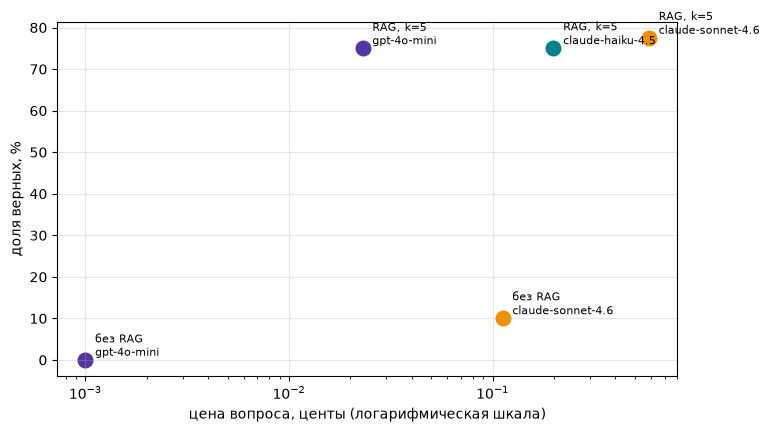

In [43]:
money_chart(table, "img/money_rag.png");

,config,model,n,accuracy,cost_per_task,cost_per_correct
0,k=1,gpt-4o-mini,40,0.650,0.00007,0.00010
1,k=3,gpt-4o-mini,40,0.725,0.00015,0.00021
2,k=5,gpt-4o-mini,40,0.725,0.00018,0.00025
3,k=10,gpt-4o-mini,40,0.750,0.00035,0.00047


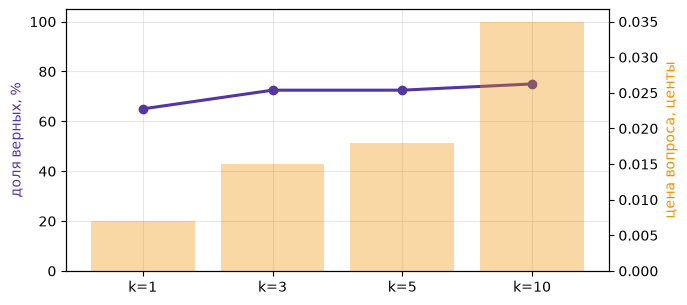

In [44]:
sweep = pd.concat([evaluate(lambda q, m, k=k: rag_answer(q, m, k), sample, f"k={k}", MODELS["cheap"]) for k in (1, 3, 5, 10)], ignore_index=True)
sweep_table = report(sweep)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(sweep_table["config"], sweep_table["accuracy"] * 100, marker="o", lw=2.2, color=COLORS["violet"]); ax.set_ylabel("доля верных, %", color=COLORS["violet"])
ax2 = ax.twinx(); ax2.bar(sweep_table["config"], sweep_table["cost_per_task"] * 100, alpha=0.35, color=COLORS["amber"]); ax2.set_ylabel("цена вопроса, центы", color=COLORS["amber"])
ax.set_ylim(0, 105); ax.grid(alpha=0.3)
sweep_table

## Разбор провалов


In [45]:
def diagnose(results):
    wrong = results[~results["correct"] & results["config"].str.startswith("RAG")]
    return wrong.groupby("model").agg(не_нашли=("found", lambda s: int((~s).sum())), нашли_но_ответ_неверный=("found", "sum"))

diagnose(results)

,не_нашли,нашли_но_ответ_неверный
model,,
claude-haiku-4.5,9,1
claude-sonnet-4.6,9,0
gpt-4o-mini,8,2


In [46]:
results[~results["correct"] & (results["config"] == "RAG, k=5")][["model", "gold", "answer", "found"]]

,model,gold,answer,found
82,gpt-4o-mini,13th,NOT_FOUND,False
85,gpt-4o-mini,youngest polesitter,Youngest Formula One polesitter.,False
87,gpt-4o-mini,20th,NOT_FOUND,False
91,gpt-4o-mini,Hulkenberg,Nico Hülkenberg.,False
92,gpt-4o-mini,skid block,NOT_FOUND.,False
110,gpt-4o-mini,Verstappen,Lando Norris.,True
111,gpt-4o-mini,Norris and Piastri,Lando Norris and Oscar Piastri.,False
114,gpt-4o-mini,Kimi Antonelli,NOT_FOUND.,False
116,gpt-4o-mini,Arvid Lindblad,NOT_FOUND,True
119,gpt-4o-mini,Norris,NOT_FOUND,False


In [47]:
def tokens(text):
    return re.findall(r"\w+", text.lower())

def build_keyword_index(texts):
    docs = [set(tokens(text)) for text in texts]
    df = {}
    for d in docs:
        for w in d:
            df[w] = df.get(w, 0) + 1
    return docs, {w: np.log(len(docs) / n) for w, n in df.items()}

def keyword_search(query, docs, idf, k=20):
    q = set(tokens(query))
    scores = np.array([sum(idf.get(w, 0.0) for w in q & d) for d in docs])
    return [int(i) for i in np.argsort(-scores)[:k]]

In [ ]:
def rrf(rankings, k=5, K=60):
    scores = {}
    for ranking in rankings:
        for rank, idx in enumerate(ranking):
            scores[idx] = scores.get(idx, 0.0) + 1 / (K + rank + 1)

    return sorted(scores, key=scores.get, reverse=True)[:k]

I1013 00:19:55.777586    9281 chttp2_transport.cc:1400] ipv4:127.0.0.1:33585: Got goaway [11] err=UNAVAILABLE:GOAWAY received; Error code: 11; Debug Text: too_many_pings {http2_error:11}
E1013 00:19:55.779293    9281 chttp2_transport.cc:1432] ipv4:127.0.0.1:33585: Received a GOAWAY with error code ENHANCE_YOUR_CALM and debug data equal to "too_many_pings". Current keepalive time (before throttling): 320000ms


,нарезка,поиск,recall@1,recall@5
0,по 400 символов,только вектор,0.22,0.38
1,по 400 символов,только слова,0.22,0.45
2,по 400 символов,гибрид RRF,0.25,0.40
3,по 1200 символов,только вектор,0.62,0.72
4,по 1200 символов,только слова,0.32,0.68
5,по 1200 символов,гибрид RRF,0.60,0.70
6,по строкам,только вектор,0.32,0.40
7,по строкам,только слова,0.35,0.68
8,по строкам,гибрид RRF,0.35,0.65


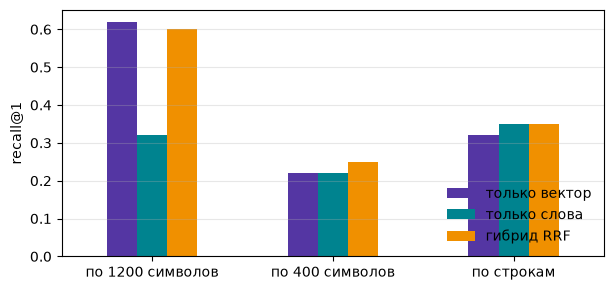

In [49]:
def recall_of(rankings, chunks, k=5):
    return float(np.mean([any(is_gold(chunks[i], t) for i in r[:k]) for r, t in zip(rankings, tasks)]))

rows = []
for cut, chunks, vectors, texts in [("по 400 символов", char_chunks_400, char_vecs_400, [c["text"] for c in char_chunks_400]),
                                    ("по 1200 символов", char_chunks_1200, char_vecs_1200, [c["text"] for c in char_chunks_1200]),
                                    ("по строкам", line_chunks, line_vecs, [emb_text(c) for c in line_chunks])]:
    docs, idf = build_keyword_index(texts)
    by_vector = [[i for i, _ in search_numpy(q, vectors, 20)] for q in q_vecs]
    by_words = [keyword_search(t["question"], docs, idf, 20) for t in tasks]
    by_hybrid = [rrf([v, w], 20) for v, w in zip(by_vector, by_words)]
    rows += [{"нарезка": cut, "поиск": name, "recall@1": recall_of(r, chunks, 1), "recall@5": recall_of(r, chunks, 5)}
             for name, r in [("только вектор", by_vector), ("только слова", by_words), ("гибрид RRF", by_hybrid)]]
hybrid = pd.DataFrame(rows).round(2)
ax = hybrid.pivot(index="нарезка", columns="поиск", values="recall@1")[["только вектор", "только слова", "гибрид RRF"]].plot.bar(
    figsize=(7, 3.2), color=[COLORS["violet"], COLORS["teal"], COLORS["amber"]], rot=0)
ax.set_ylabel("recall@1"); ax.set_xlabel(""); ax.legend(frameon=False, loc="lower right"); ax.grid(alpha=0.3, axis="y")
hybrid

In [51]:
UNANSWERABLE = ["Who won the 2026 Singapore Grand Prix?",
                "Which driver achieved pole position at the 2026 Japanese Grand Prix?",
                "Which team made its official race debut as a full constructor at the 2026 United States Grand Prix?",
                "Who won the sprint race at the 2026 Mexico City Grand Prix?",
                "Which driver suffered a retirement due to a power unit failure at the 2026 São Paulo Grand Prix?",
                "How many points did Kimi Antonelli have in the standings after winning the 2026 Las Vegas Grand Prix?",
                "Which driver was disqualified from the 2026 Qatar Grand Prix due to a plank wear infringement?", 
                "Who won the final race of the 2026 Formula One season at the Abu Dhabi Grand Prix?", 
                "Which team secured the 2026 Constructors' Championship at the Abu Dhabi Grand Prix?",
                "Which driver was announced as the new reserve driver for Ferrari for the 2027 season in December 2026?"]
refusals = [rag_answer(q, MODELS["cheap"]) for q in UNANSWERABLE]
sum("NOT_FOUND" in r["answer"] for r in refusals), [final_answer(r["answer"])[:40] for r in refusals if "NOT_FOUND" not in r["answer"]]

(10, [])

(0.743, 0.648)

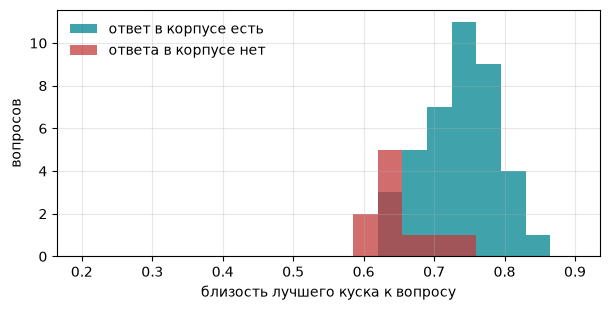

In [52]:
top_answerable = [search_numpy(q, line_vecs, 1)[0][1] for q in q_vecs]
top_unanswerable = [r["hits"][0]["score"] for r in refusals]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(top_answerable, bins=20, range=(0.2, 0.9), alpha=0.75, color=COLORS["teal"], label="ответ в корпусе есть")
ax.hist(top_unanswerable, bins=20, range=(0.2, 0.9), alpha=0.75, color=COLORS["red"], label="ответа в корпусе нет")
ax.set_xlabel("близость лучшего куска к вопросу"); ax.set_ylabel("вопросов"); ax.legend(frameon=False); ax.grid(alpha=0.3)
round(float(np.median(top_answerable)), 3), round(float(np.median(top_unanswerable)), 3)

## Память агента
